### EIGEN VECTOR, PC, weight, comulative and explained varaince

In [2]:
import os
import numpy as np
import rasterio
from sklearn.decomposition import PCA
import pandas as pd

# =========================================================
# 1. BASE DIRECTORY
# =========================================================

BASE_DIR = r"C:\Users\gerii\Documents\projects\tekeze\indices\ALIGNED_5550m"

OUTPUT_DIR = r"C:\Users\gerii\Documents\projects\tekeze\indices\PCA_RESULTS"

os.makedirs(OUTPUT_DIR, exist_ok=True)

# =========================================================
# 2. VARIABLES
# =========================================================

VARIABLES = [
    "SPI3",
    "SPEI3",
    "VCI",
    "TCI"
]

# =========================================================
# 3. DATE RANGE
# =========================================================

dates = []

for year in range(2000, 2026):

    for month in range(1, 13):

        if year == 2000 and month < 2:
            continue

        if year == 2025 and month > 12:
            continue

        dates.append(f"{year}_{month:02d}")

# =========================================================
# 4. READ RASTER
# =========================================================

def read_raster(path):

    with rasterio.open(path) as src:

        arr = src.read(1).astype(np.float32)

        nodata = src.nodata

        if nodata is not None:
            arr[arr == nodata] = np.nan

    return arr

# =========================================================
# 5. BUILD PCA MATRIX
# =========================================================

matrix = []

valid_dates = []

print("Building PCA matrix...")

for date in dates:

    row = []

    valid = True

    for var in VARIABLES:

        path = os.path.join(
            BASE_DIR,
            var,
            f"{var}_{date}.tif"
        )

        if not os.path.exists(path):

            print(f"Missing: {path}")

            valid = False
            break

        arr = read_raster(path)

        # Basin average
        value = np.nanmean(arr)

        if np.isnan(value):

            valid = False
            break

        row.append(value)

    if valid:

        matrix.append(row)

        valid_dates.append(date)

# =========================================================
# 6. CONVERT TO NUMPY
# =========================================================

X = np.array(matrix)

print("\nFinal Matrix Shape:", X.shape)

# Expected:
# (311, 4)

# =========================================================
# 7. STANDARDIZATION
# =========================================================

mean = np.mean(X, axis=0)

std = np.std(X, axis=0)

Xz = (X - mean) / std

# =========================================================
# 8. CORRELATION MATRIX
# =========================================================

corr_matrix = np.corrcoef(Xz.T)

corr_df = pd.DataFrame(
    corr_matrix,
    index=VARIABLES,
    columns=VARIABLES
)

print("\n==============================")
print("CORRELATION MATRIX")
print("==============================")

print(corr_df.round(3))

corr_df.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "Correlation_Matrix.csv"
    )
)

# =========================================================
# 9. PCA
# =========================================================

pca = PCA(n_components=4)

pca.fit(Xz)

# =========================================================
# 10. EIGENVALUES
# =========================================================

eigenvalues = pca.explained_variance_

eigen_df = pd.DataFrame({
    "PC":
        [f"PC{i+1}" for i in range(4)],
    "Eigenvalue":
        eigenvalues
})

print("\n==============================")
print("EIGENVALUES")
print("==============================")

print(eigen_df.round(4))

eigen_df.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "Eigenvalues.csv"
    ),
    index=False
)

# =========================================================
# 11. EIGENVECTOR MATRIX
# =========================================================

loadings = pca.components_.T

loading_df = pd.DataFrame(
    loadings,
    index=VARIABLES,
    columns=[
        "PC1",
        "PC2",
        "PC3",
        "PC4"
    ]
)

print("\n==============================")
print("EIGENVECTOR / LOADING MATRIX")
print("==============================")

print(loading_df.round(4))

loading_df.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "Eigenvector_Loadings.csv"
    )
)

# =========================================================
# 12. EXPLAINED VARIANCE
# =========================================================

variance_ratio = pca.explained_variance_ratio_ * 100

variance_df = pd.DataFrame({
    "PC":
        [f"PC{i+1}" for i in range(4)],
    "Explained_Variance_%":
        variance_ratio
})

print("\n==============================")
print("EXPLAINED VARIANCE (%)")
print("==============================")

print(variance_df.round(2))

variance_df.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "Explained_Variance.csv"
    ),
    index=False
)

# =========================================================
# 13. CUMULATIVE VARIANCE
# =========================================================

cumulative = np.cumsum(variance_ratio)

cum_df = pd.DataFrame({
    "PC":
        [f"PC{i+1}" for i in range(4)],
    "Cumulative_Variance_%":
        cumulative
})

print("\n==============================")
print("CUMULATIVE VARIANCE (%)")
print("==============================")

print(cum_df.round(2))

cum_df.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "Cumulative_Variance.csv"
    ),
    index=False
)

# =========================================================
# 14. CDI WEIGHTS (PC1)
# =========================================================

pc1 = pca.components_[0]

weights = (pc1 ** 2) / np.sum(pc1 ** 2)

weights_df = pd.DataFrame({
    "Variable": VARIABLES,
    "PC1_Loading": pc1,
    "CDI_Weight": weights
})

print("\n==============================")
print("CDI WEIGHTS")
print("==============================")

print(weights_df.round(4))

weights_df.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "CDI_Weights.csv"
    ),
    index=False
)

# =========================================================
# 15. PCA SCORES
# =========================================================

scores = pca.transform(Xz)

scores_df = pd.DataFrame(
    scores,
    columns=[
        "PC1",
        "PC2",
        "PC3",
        "PC4"
    ]
)

scores_df.insert(0, "Date", valid_dates)

print("\n==============================")
print("FIRST 10 PCA SCORES")
print("==============================")

print(scores_df.head(10).round(4))

scores_df.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "PCA_Scores.csv"
    ),
    index=False
)

# =========================================================
# 16. FINISHED
# =========================================================

print("\n======================================")
print("BLOCK 1 COMPLETED SUCCESSFULLY")
print("PCA MODEL GENERATED")
print("======================================")

Building PCA matrix...

Final Matrix Shape: (311, 4)

CORRELATION MATRIX
        SPI3  SPEI3    VCI    TCI
SPI3   1.000  0.870  0.929  0.789
SPEI3  0.870  1.000  0.822  0.833
VCI    0.929  0.822  1.000  0.903
TCI    0.789  0.833  0.903  1.000

EIGENVALUES
    PC  Eigenvalue
0  PC1      3.5852
1  PC2      0.2188
2  PC3      0.1865
3  PC4      0.0224

EIGENVECTOR / LOADING MATRIX
          PC1     PC2     PC3     PC4
SPI3   0.5024 -0.5435 -0.3799 -0.5549
SPEI3  0.4928 -0.3504  0.7462  0.2785
VCI    0.5116  0.1507 -0.5170  0.6695
TCI    0.4930  0.7478  0.1777 -0.4078

EXPLAINED VARIANCE (%)
    PC  Explained_Variance_%
0  PC1             89.339996
1  PC2              5.450000
2  PC3              4.650000
3  PC4              0.560000

CUMULATIVE VARIANCE (%)
    PC  Cumulative_Variance_%
0  PC1              89.339996
1  PC2              94.800003
2  PC3              99.440002
3  PC4             100.000000

CDI WEIGHTS
  Variable  PC1_Loading  CDI_Weight
0     SPI3       0.5024      0.2524


### PCA-Based Composite Drought Index Performance

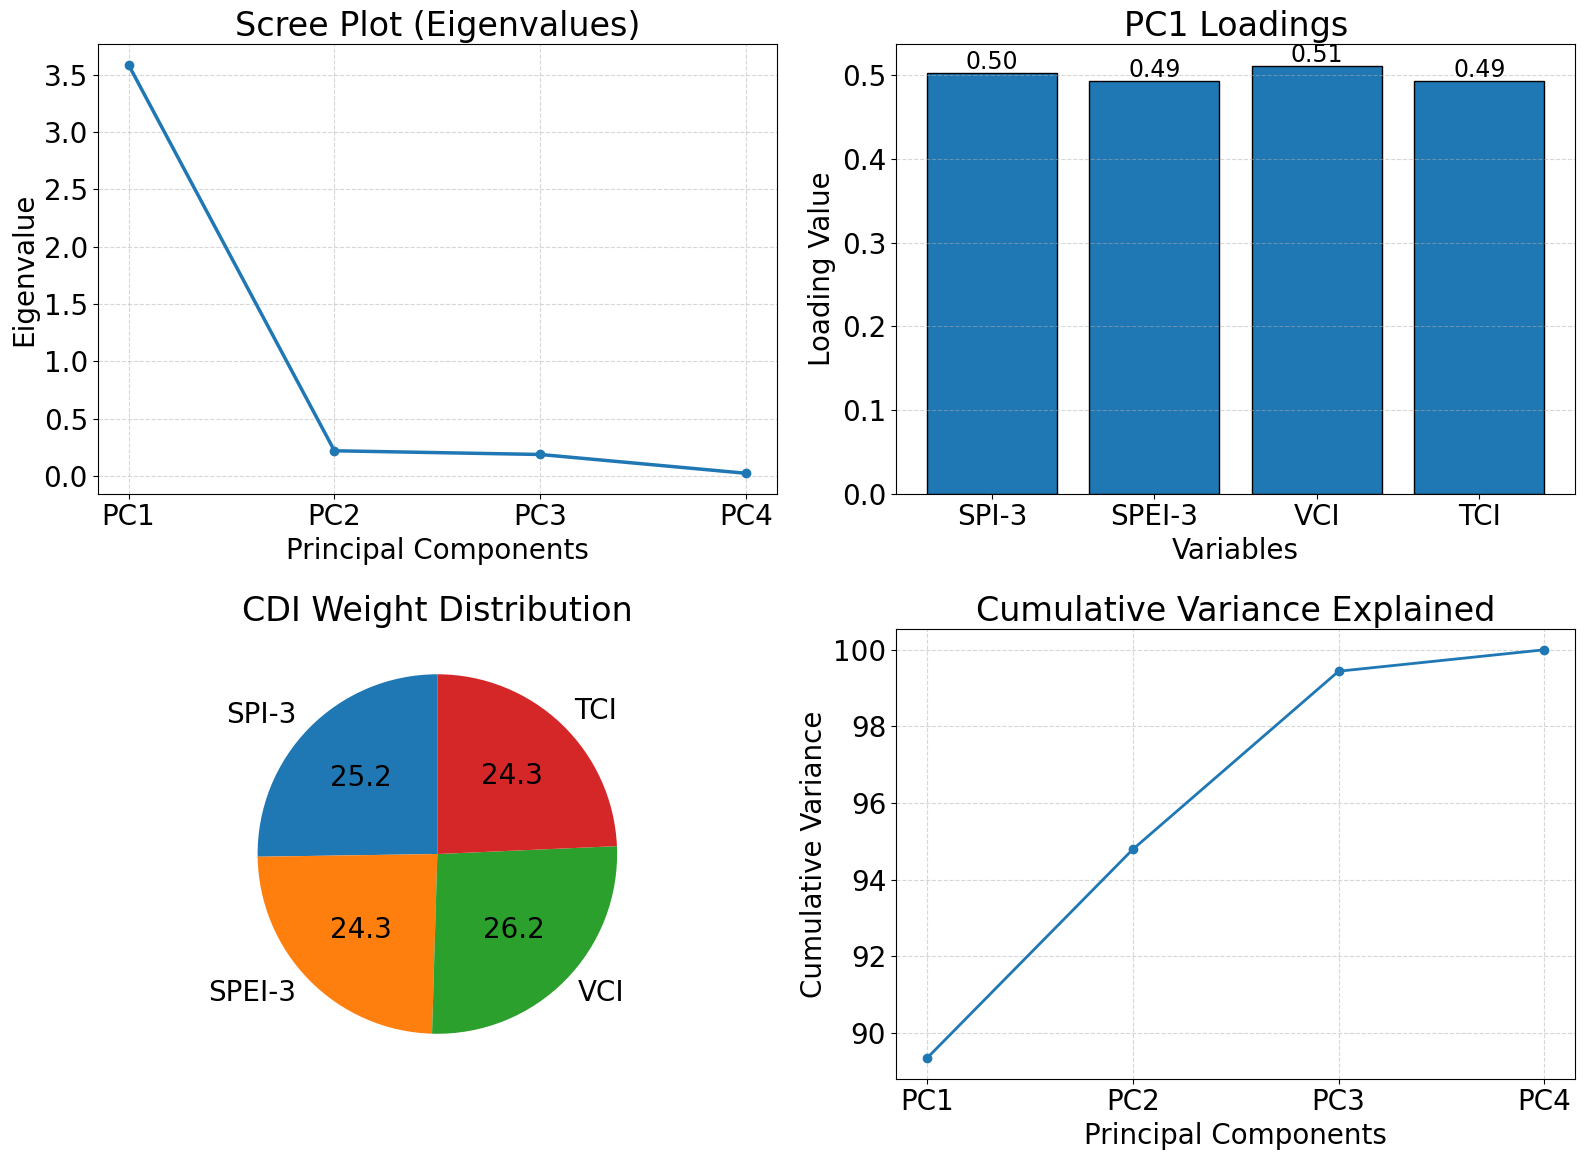

Figure saved at:
C:\Users\gerii\Documents\projects\tekeze\indices\CDI_OUTPUT_CLIPPED\PCA_4Panel_Results.png


In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt

# =============================
# DATA
# =============================
pcs = ['PC1', 'PC2', 'PC3', 'PC4']

eigenvalues = [3.5852, 0.2188, 0.1865, 0.0224]

explained_variance = [89.34, 5.45, 4.65, 0.56]
cumulative_variance = np.cumsum(explained_variance)

variables = ['SPI-3', 'SPEI-3', 'VCI', 'TCI']
pc1_loadings = [0.5024, 0.4928, 0.5116, 0.4930]

weights = [25.24, 24.29, 26.17, 24.30]

# =============================
# OUTPUT FOLDER
# =============================
output_folder = r"C:\Users\gerii\Documents\projects\tekeze\indices\CDI_OUTPUT_CLIPPED"
os.makedirs(output_folder, exist_ok=True)

output_file = os.path.join(output_folder, "PCA_4Panel_Results.png")

# =============================
# FONT SETTINGS
# =============================
plt.rcParams.update({
    'font.size': 20
})

# =============================
# FIGURE SETUP
# =============================
fig, axs = plt.subplots(2, 2, figsize=(16, 12))

# =============================
# 1. SCREE PLOT (Eigenvalues)
# =============================
axs[0, 0].plot(pcs, eigenvalues, marker='o', linewidth=2.5)
axs[0, 0].set_title('Scree Plot (Eigenvalues)')
axs[0, 0].set_xlabel('Principal Components')
axs[0, 0].set_ylabel('Eigenvalue')
axs[0, 0].grid(True, linestyle='--', alpha=0.5)

# =============================
# 2. PC1 LOADINGS
# =============================
axs[0, 1].bar(variables, pc1_loadings, edgecolor='black')
axs[0, 1].set_title('PC1 Loadings')
axs[0, 1].set_xlabel('Variables')
axs[0, 1].set_ylabel('Loading Value')
axs[0, 1].grid(axis='y', linestyle='--', alpha=0.5)

for i, v in enumerate(pc1_loadings):
    axs[0, 1].text(i, v + 0.005, f"{v:.2f}", ha='center', fontsize=17)

# =============================
# 3. CDI WEIGHTS (PIE CHART)
# =============================
axs[1, 0].pie(
    weights,
    labels=variables,
    autopct='%1.1f',
    startangle=90
)
axs[1, 0].set_title('CDI Weight Distribution') # normalized PCA weights 

# =============================
# 4. CUMULATIVE VARIANCE
# =============================
axs[1, 1].plot(pcs, cumulative_variance, marker='o', linewidth=2)
axs[1, 1].set_title('Cumulative Variance Explained')
axs[1, 1].set_xlabel('Principal Components')
axs[1, 1].set_ylabel('Cumulative Variance')
axs[1, 1].grid(True, linestyle='--', alpha=0.5)

# =============================
# FINAL LAYOUT
# =============================
plt.tight_layout()

# =============================
# SAVE FIGURE
# =============================
plt.savefig(
    output_file,
    dpi=300,
    bbox_inches='tight'
)

plt.show()

print("Figure saved at:")
print(output_file)

### CDI Computation and normalization

In [5]:
import os
import numpy as np
import rasterio
import pandas as pd
from tqdm import tqdm

# =========================================================
# 1. BASE DIRECTORY
# =========================================================

BASE_DIR = r"C:\Users\gerii\Documents\projects\tekeze\indices\ALIGNED_5550m"

OUTPUT_DIR = r"C:\Users\gerii\Documents\projects\tekeze\indices\CDI_OUTPUT"

WEIGHT_FILE = r"C:\Users\gerii\Documents\projects\tekeze\indices\PCA_RESULTS\CDI_Weights.csv"

os.makedirs(OUTPUT_DIR, exist_ok=True)

# =========================================================
# 2. VARIABLES
# =========================================================

VARIABLES = [
    "SPI3",
    "SPEI3",
    "VCI",
    "TCI"
]

# =========================================================
# 3. LOAD PCA WEIGHTS
# =========================================================

weights_df = pd.read_csv(WEIGHT_FILE)

weights = weights_df["CDI_Weight"].values

print("\nPCA Weights:")

for var, w in zip(VARIABLES, weights):

    print(f"{var}: {w:.4f}")

# =========================================================
# 4. DATE RANGE
# =========================================================

dates = []

for year in range(2000, 2026):

    for month in range(1, 13):

        if year == 2000 and month < 2:
            continue

        if year == 2025 and month > 12:
            continue

        dates.append(f"{year}_{month:02d}")

# =========================================================
# 5. READ RASTER
# =========================================================

def read_raster(path):

    with rasterio.open(path) as src:

        arr = src.read(1).astype(np.float32)

        nodata = src.nodata

        if nodata is not None:

            arr[arr == nodata] = np.nan

        profile = src.profile

    return arr, profile

# =========================================================
# 6. COMPUTE RAW CDI
# =========================================================

print("\nComputing CDI rasters...")

raw_cdi_list = []

reference_profile = None

for date in tqdm(dates):

    layers = []

    valid = True

    # -----------------------------------------------------
    # LOAD STANDARDIZED INDICES
    # -----------------------------------------------------

    for var in VARIABLES:

        path = os.path.join(
            BASE_DIR,
            var,
            f"{var}_{date}.tif"
        )

        if not os.path.exists(path):

            print(f"Missing: {path}")

            valid = False
            break

        arr, profile = read_raster(path)

        if reference_profile is None:

            reference_profile = profile

        layers.append(arr)

    if not valid:

        continue

    # -----------------------------------------------------
    # STACK VARIABLES
    # -----------------------------------------------------

    stack = np.stack(layers, axis=-1)

    # shape:
    # rows × cols × 4

    # -----------------------------------------------------
    # CDI COMPUTATION
    # -----------------------------------------------------

    cdi = np.full(
        stack.shape[:2],
        np.nan,
        dtype=np.float32
    )

    valid_mask = ~np.isnan(stack).any(axis=-1)

    cdi[valid_mask] = np.sum(
        stack[valid_mask] * weights,
        axis=1
    )

    raw_cdi_list.append(cdi)

# =========================================================
# 7. GLOBAL NORMALIZATION (-4 TO 4)
# =========================================================

print("\nNormalizing CDI...")

all_values = np.concatenate([
    x[np.isfinite(x)]
    for x in raw_cdi_list
])

global_min = np.min(all_values)

global_max = np.max(all_values)

print(f"Global Min: {global_min:.4f}")
print(f"Global Max: {global_max:.4f}")

normalized_list = []

for cdi in raw_cdi_list:

    norm = np.full_like(cdi, np.nan)

    valid = np.isfinite(cdi)

    norm[valid] = (
        8 *
        (
            (cdi[valid] - global_min)
            /
            (global_max - global_min)
        )
    ) - 4

    normalized_list.append(norm)

# =========================================================
# 8. SAVE CDI RASTERS
# =========================================================

print("\nSaving CDI rasters...")

for i, date in enumerate(tqdm(dates)):

    output_path = os.path.join(
        OUTPUT_DIR,
        f"CDI_{date}.tif"
    )

    profile = reference_profile.copy()

    profile.update(
        dtype=rasterio.float32,
        count=1,
        compress='lzw',
        nodata=np.nan
    )

    with rasterio.open(
        output_path,
        'w',
        **profile
    ) as dst:

        dst.write(
            normalized_list[i].astype(np.float32),
            1
        )

print("\n===================================")
print("CDI GENERATION COMPLETED")
print("===================================")


PCA Weights:
SPI3: 0.2524
SPEI3: 0.2429
VCI: 0.2617
TCI: 0.2430

Computing CDI rasters...


100%|████████████████████████████████████████████████████████████████████████████████| 311/311 [00:26<00:00, 11.85it/s]



Normalizing CDI...
Global Min: -0.9828
Global Max: 1.8174

Saving CDI rasters...


100%|████████████████████████████████████████████████████████████████████████████████| 311/311 [00:18<00:00, 16.51it/s]


CDI GENERATION COMPLETED


### fill empty pixel with kringing interpolation

In [6]:
import os
import numpy as np
import rasterio
from scipy.interpolate import griddata
from tqdm import tqdm

# =========================================================
# 1. INPUT / OUTPUT FOLDERS
# =========================================================

INPUT_DIR = r"C:\Users\gerii\Documents\projects\tekeze\indices\CDI_OUTPUT"

OUTPUT_DIR = r"C:\Users\gerii\Documents\projects\tekeze\indices\CDI_OUTPUT_FILLED"

os.makedirs(OUTPUT_DIR, exist_ok=True)

# =========================================================
# 2. LIST CDI FILES
# =========================================================

files = sorted([
    f for f in os.listdir(INPUT_DIR)
    if f.endswith(".tif")
])

print("Total CDI files:", len(files))

# =========================================================
# 3. FILL FUNCTION
# =========================================================

def fill_nodata_kriging_like(data):

    # ---------------------------------------------
    # VALID PIXELS
    # ---------------------------------------------

    valid_mask = np.isfinite(data)

    if np.sum(valid_mask) == 0:
        return data

    # ---------------------------------------------
    # GRID COORDINATES
    # ---------------------------------------------

    rows, cols = data.shape

    x, y = np.meshgrid(
        np.arange(cols),
        np.arange(rows)
    )

    # ---------------------------------------------
    # KNOWN POINTS
    # ---------------------------------------------

    known_x = x[valid_mask]
    known_y = y[valid_mask]

    known_values = data[valid_mask]

    # ---------------------------------------------
    # MISSING POINTS
    # ---------------------------------------------

    missing_mask = ~valid_mask

    missing_x = x[missing_mask]
    missing_y = y[missing_mask]

    # ---------------------------------------------
    # INTERPOLATION
    # ---------------------------------------------

    interpolated = griddata(
        points=(known_x, known_y),
        values=known_values,
        xi=(missing_x, missing_y),
        method='linear'
    )

    # ---------------------------------------------
    # FILL DATA
    # ---------------------------------------------

    filled = data.copy()

    filled[missing_mask] = interpolated

    # ---------------------------------------------
    # SECOND PASS (nearest)
    # fills remaining edge NaNs
    # ---------------------------------------------

    remaining_nan = np.isnan(filled)

    if np.any(remaining_nan):

        nearest_fill = griddata(
            points=(known_x, known_y),
            values=known_values,
            xi=(x[remaining_nan], y[remaining_nan]),
            method='nearest'
        )

        filled[remaining_nan] = nearest_fill

    return filled

# =========================================================
# 4. PROCESS ALL FILES
# =========================================================

print("\nFilling empty pixels...")

for file in tqdm(files):

    input_path = os.path.join(INPUT_DIR, file)

    output_path = os.path.join(OUTPUT_DIR, file)

    # -----------------------------------------------------
    # READ
    # -----------------------------------------------------

    with rasterio.open(input_path) as src:

        data = src.read(1).astype(np.float32)

        profile = src.profile

        nodata = src.nodata

        if nodata is not None:

            data[data == nodata] = np.nan

    # -----------------------------------------------------
    # INTERPOLATE
    # -----------------------------------------------------

    filled = fill_nodata_kriging_like(data)

    # -----------------------------------------------------
    # SAVE
    # -----------------------------------------------------

    profile.update(
        dtype=rasterio.float32,
        compress='lzw',
        nodata=np.nan
    )

    with rasterio.open(
        output_path,
        'w',
        **profile
    ) as dst:

        dst.write(
            filled.astype(np.float32),
            1
        )

print("\n===================================")
print("EMPTY PIXELS FILLED SUCCESSFULLY")
print("===================================")

Total CDI files: 311

Filling empty pixels...


100%|████████████████████████████████████████████████████████████████████████████████| 311/311 [01:01<00:00,  5.04it/s]


EMPTY PIXELS FILLED SUCCESSFULLY


### clipping

In [7]:
import os
import numpy as np
import rasterio
import geopandas as gpd
from rasterio.mask import mask
from tqdm import tqdm

# =========================================================
# INPUT / OUTPUT
# =========================================================

INPUT_DIR = r"C:\Users\gerii\Documents\projects\tekeze\indices\CDI_OUTPUT_FILLED"

OUTPUT_DIR = r"C:\Users\gerii\Documents\projects\tekeze\indices\CDI_OUTPUT_CLIPPED"

SHAPEFILE = r"C:\Users\geri geri\Desktop\study_area\tekeze\tekeze.shp"

os.makedirs(OUTPUT_DIR, exist_ok=True)

# =========================================================
# LOAD SHAPEFILE
# =========================================================

basin = gpd.read_file(SHAPEFILE)

# IMPORTANT: keep CRS as raster CRS later
geoms = basin.geometry.values

# =========================================================
# GET FILES
# =========================================================

files = sorted([
    f for f in os.listdir(INPUT_DIR)
    if f.endswith(".tif")
])

print("CDI files found:", len(files))

# =========================================================
# CLIPPING FUNCTION
# =========================================================

def clip_raster(in_path, out_path):

    with rasterio.open(in_path) as src:

        # align CRS if needed
        if basin.crs != src.crs:
            gdf = basin.to_crs(src.crs)
            geom = gdf.geometry.values
        else:
            geom = geoms

        out_img, out_transform = mask(
            src,
            geom,
            crop=True,
            nodata=np.nan
        )

        out_meta = src.meta.copy()

        out_meta.update({
            "height": out_img.shape[1],
            "width": out_img.shape[2],
            "transform": out_transform,
            "nodata": np.nan
        })

    with rasterio.open(out_path, "w", **out_meta) as dst:
        dst.write(out_img)

# =========================================================
# PROCESS ALL CDI FILES
# =========================================================

print("\nClipping CDI rasters to Tekeze basin...")

for f in tqdm(files):

    in_file = os.path.join(INPUT_DIR, f)
    out_file = os.path.join(OUTPUT_DIR, f)

    try:
        clip_raster(in_file, out_file)

    except Exception as e:
        print("FAILED:", f, "->", e)

print("\nDONE: CDI rasters clipped successfully.")

CDI files found: 311

Clipping CDI rasters to Tekeze basin...


100%|████████████████████████████████████████████████████████████████████████████████| 311/311 [00:59<00:00,  5.25it/s]


DONE: CDI rasters clipped successfully.


Files found: 12


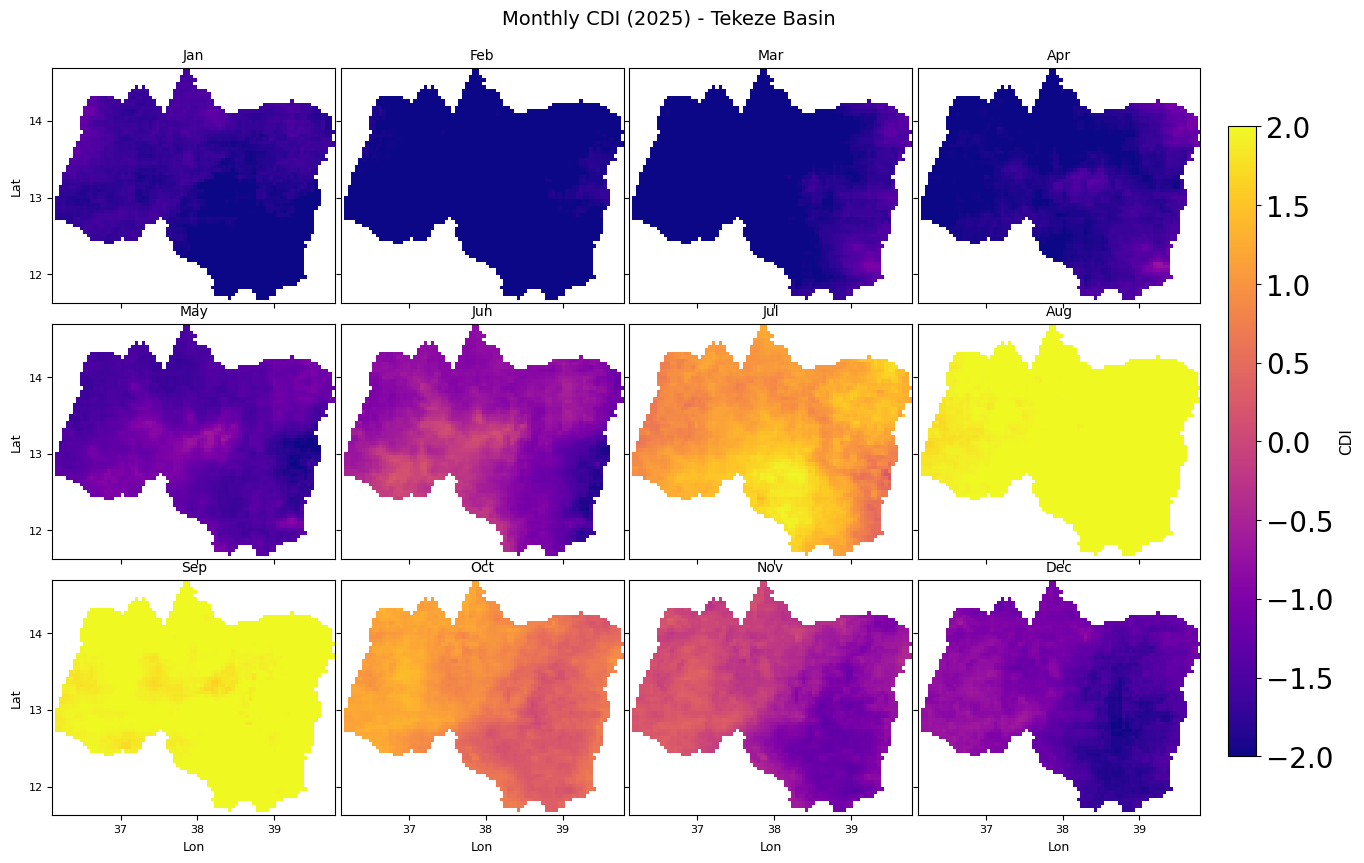

In [11]:
import os
import rasterio
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator

# ======================
# FOLDER (CDI OUTPUT)
# ======================
folder = r"C:\Users\gerii\Documents\projects\tekeze\indices\CDI_OUTPUT_CLIPPED"

year = "2025"

files = sorted([
    f for f in os.listdir(folder)
    if f.startswith(f"CDI_{year}") and f.endswith(".tif")
])

print("Files found:", len(files))

# ======================
# FIGURE
# ======================
fig, axes = plt.subplots(3, 4, figsize=(14, 9))
axes = axes.flatten()

months = ["Jan","Feb","Mar","Apr","May","Jun",
          "Jul","Aug","Sep","Oct","Nov","Dec"]

# CDI RANGE (same concept as standardized drought index)
vmin = -2
vmax = 2

# ======================
# PLOT LOOP
# ======================
for i, f in enumerate(files):

    path = os.path.join(folder, f)

    with rasterio.open(path) as src:
        data = src.read(1).astype("float32")

        # mask nodata and extreme artifacts
        data[np.abs(data) > 10] = np.nan

        bounds = src.bounds
        extent = [bounds.left, bounds.right, bounds.bottom, bounds.top]

    ax = axes[i]

    im = ax.imshow(
        data,
        extent=extent,
        origin="upper",
        cmap="plasma",   # dry=red, wet=blue (same as SPEI style)
        vmin=vmin,
        vmax=vmax
    )

    ax.set_title(months[i], fontsize=10)

    # ======================
    # 1-degree grid
    # ======================
    ax.xaxis.set_major_locator(MultipleLocator(1))
    ax.yaxis.set_major_locator(MultipleLocator(1))
    ax.tick_params(labelsize=8)

    # ======================
    # AXIS STYLE
    # ======================
    row = i // 4
    col = i % 4

    if col == 0:
        ax.set_ylabel("Lat", fontsize=9)
    else:
        ax.set_yticklabels([])

    if row == 2:
        ax.set_xlabel("Lon", fontsize=9)
    else:
        ax.set_xticklabels([])

# ======================
# REMOVE EMPTY AXES
# ======================
for j in range(len(files), 12):
    axes[j].axis("off")

# ======================
# LAYOUT (IDENTICAL STYLE)
# ======================
plt.subplots_adjust(
    left=0.06,
    right=0.88,
    top=0.92,
    bottom=0.08,
    wspace=0.02,
    hspace=0.05
)

# ======================
# COLORBAR (RIGHT SIDE)
# ======================
cbar_ax = fig.add_axes([0.90, 0.15, 0.02, 0.7])
cbar = fig.colorbar(im, cax=cbar_ax)
cbar.set_label("CDI", fontsize=11)

# ======================
# TITLE
# ======================
plt.suptitle(f"Monthly CDI (2025) - Tekeze Basin", fontsize=14)

# ======================
# SAVE OUTPUT
# ======================
out_path = os.path.join(
    folder,
    f"CDI_{year}_map.png"
)

fig.canvas.draw()
fig.savefig(
    out_path,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

###  convert to csv

In [12]:
import os
import rasterio
import numpy as np
import pandas as pd

# ======================
# Folder
# ======================
folder = r"C:\Users\gerii\Documents\projects\tekeze\indices\CDI_OUTPUT_CLIPPED"

# ======================
# Collect files
# ======================
files = sorted([
    f for f in os.listdir(folder)
    if f.startswith("CDI_") and f.endswith(".tif")
])

dates = []
means = []

for f in files:
    try:
        parts = f.replace(".tif", "").split("_")
        year = int(parts[1])
        month = int(parts[2])

        path = os.path.join(folder, f)

        with rasterio.open(path) as src:
            data = src.read(1).astype("float32")
            data[np.isinf(data)] = np.nan

            mean_val = np.nanmean(data)

        dates.append(f"{year}-{month:02d}")
        means.append(mean_val)

    except:
        continue

# ======================
# Create DataFrame
# ======================
df = pd.DataFrame({
    "date": dates,
    "CDI_mean": means
})

# sort
df["date"] = pd.to_datetime(df["date"])
df = df.sort_values("date")

# ======================
# Save CSV
# ======================
out_csv = r"C:\Users\gerii\Documents\projects\tekeze\indices\CDI_OUTPUT_CLIPPED\CDI.csv"
df.to_csv(out_csv, index=False)

print("CSV saved:", out_csv)

CSV saved: C:\Users\gerii\Documents\projects\tekeze\indices\CDI_OUTPUT_CLIPPED\CDI.csv


## Barplot

Saved figure:
C:\Users\gerii\Documents\projects\tekeze\indices\CDI_OUTPUT_CLIPPED\CDI_barplot.png


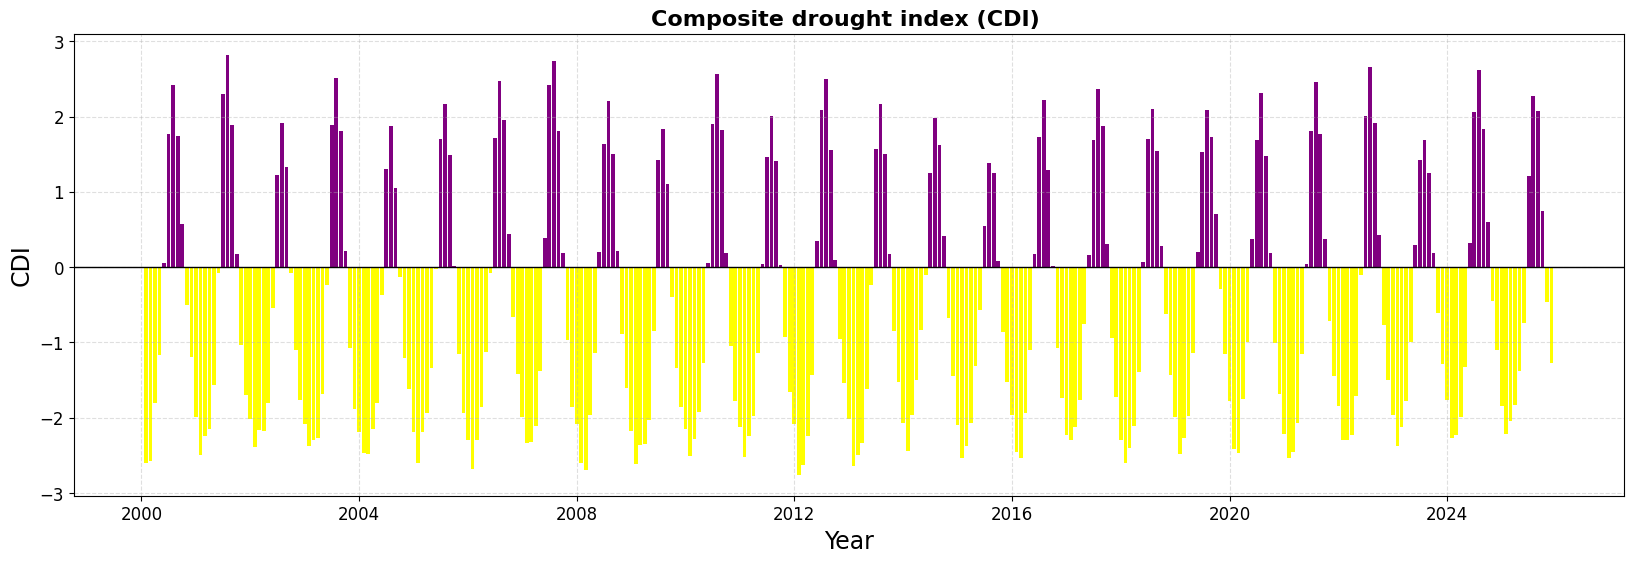

In [13]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# =====================================================
# CSV FILE PATH
# =====================================================
csv_file = r"C:\Users\gerii\Documents\projects\tekeze\indices\CDI_OUTPUT_CLIPPED\CDI.csv"

# =====================================================
# LOAD DATA
# =====================================================
df = pd.read_csv(csv_file)

df.columns = df.columns.str.strip()
df["date"] = pd.to_datetime(df["date"])

dates = df["date"]
values = df["CDI_mean"]

# =====================================================
# CORRECT CLASSIFICATION
# =====================================================
# PDSI >= 0 → no drought (blue)
# PDSI < 0  → drought (red)
colors = [
    "purple" if v >= 0 else "yellow"
    for v in values
]

# =====================================================
# PLOT
# =====================================================
fig, ax = plt.subplots(figsize=(20, 6))

ax.bar(
    dates,
    values,
    color=colors,
    width=25
)

# zero line
ax.axhline(0, color='black', linewidth=1)

# =====================================================
# STYLE
# =====================================================
ax.set_title(
    "Composite drought index (CDI) ",
    fontsize=16,
    fontweight='bold'
)

ax.set_ylabel("CDI", fontsize=17)
ax.set_xlabel("Year", fontsize=17)

ax.tick_params(axis='both', labelsize=12)

ax.grid(True, linestyle='--', alpha=0.4)

# =====================================================
# SAVE
# =====================================================
out_path = r"C:\Users\gerii\Documents\projects\tekeze\indices\CDI_OUTPUT_CLIPPED\CDI_barplot.png"

plt.savefig(out_path, dpi=300, bbox_inches='tight')

print(f"Saved figure:\n{out_path}")

plt.show()

### line plot version

Saved figure:
C:\Users\gerii\Documents\projects\tekeze\indices\CDI_OUTPUT_CLIPPED\CDI_lineplot.png


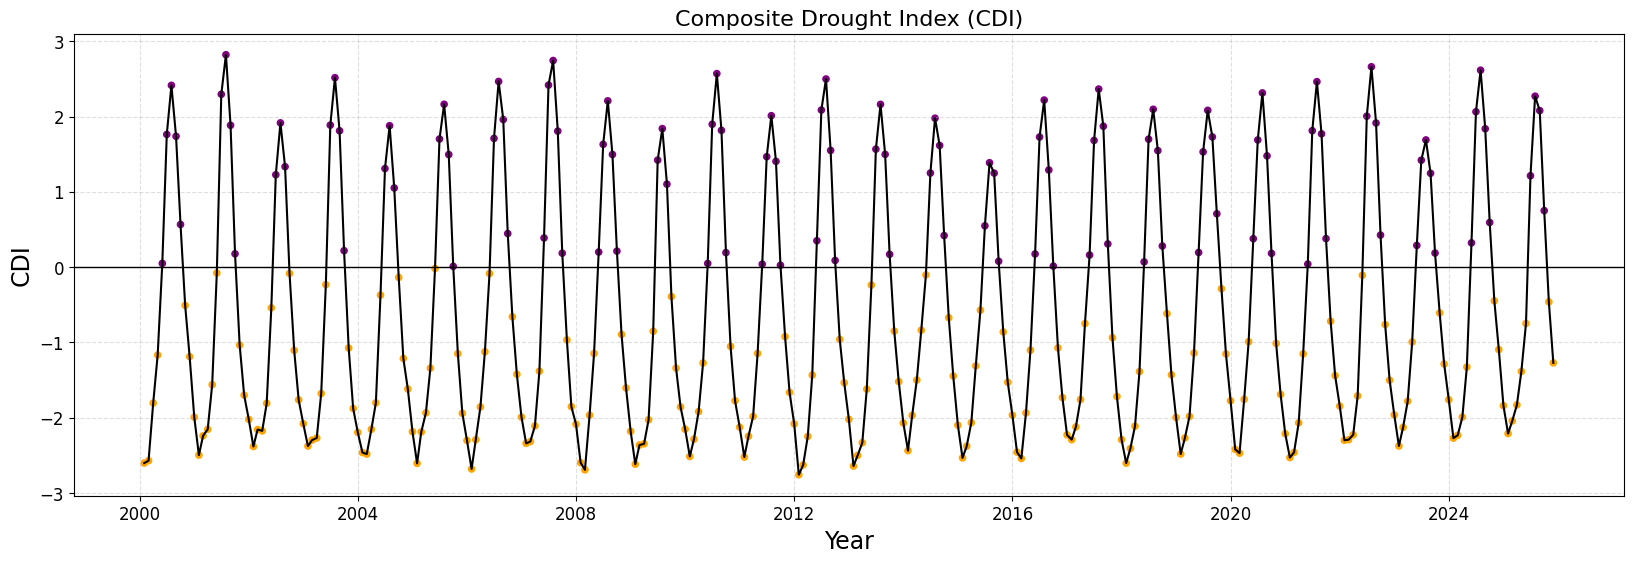

In [14]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# =====================================================
# CSV FILE PATH
# =====================================================
csv_file = r"C:\Users\gerii\Documents\projects\tekeze\indices\CDI_OUTPUT_CLIPPED\CDI.csv"

# =====================================================
# LOAD DATA
# =====================================================
df = pd.read_csv(csv_file)

df.columns = df.columns.str.strip()
df["date"] = pd.to_datetime(df["date"])

dates = df["date"]
values = df["CDI_mean"]

# =====================================================
# COLOR CLASSIFICATION
# =====================================================
colors = [
    "purple" if v >= 0 else "orange"
    for v in values
]

# =====================================================
# PLOT (LINE PLOT)
# =====================================================
fig, ax = plt.subplots(figsize=(20, 6))

# main line
ax.plot(
    dates,
    values,
    color="black",
    linewidth=1.5
)

# colored points (to show drought intensity)
ax.scatter(
    dates,
    values,
    c=colors,
    s=20
)

# zero line
ax.axhline(0, color='black', linewidth=1)

# =====================================================
# STYLE
# =====================================================
ax.set_title(
    "Composite Drought Index (CDI)",
    fontsize=16
)

ax.set_ylabel("CDI", fontsize=17)
ax.set_xlabel("Year", fontsize=17)

ax.tick_params(axis='both', labelsize=12)

ax.grid(True, linestyle='--', alpha=0.4)

# =====================================================
# SAVE
# =====================================================
out_path = r"C:\Users\gerii\Documents\projects\tekeze\indices\CDI_OUTPUT_CLIPPED\CDI_lineplot.png"

plt.savefig(out_path, dpi=300, bbox_inches='tight')

print(f"Saved figure:\n{out_path}")

plt.show()